# Reproducing the paper's tables and figures
*Confirmation time in a permissioned retail CBDC: a queueing model validated on a Hyperledger Fabric testbed*

This notebook reads the saved results in `model/` and `results/` and rebuilds the main tables and all figures in about a
minute. It does not rerun the long simulations or the testbed; the runners that produced the saved files are listed in
`README.md`. All service parameters are those measured on the testbed.

In [1]:
import sys, json, csv, re, subprocess, numpy as np, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, 'model')
from cbdc_v2_params import PIPE, B_CHOSEN, LAM_DESIGN
from cbdc_v2_formulas import end_to_end, stage_rhos, capacities
pd.set_option('display.precision', 2); pd.set_option('display.width', 160)
J = lambda f: json.load(open('model/' + f))
stats = pd.read_csv('results/campaign_stats.csv'); rounds = pd.read_csv('results/campaign_rounds.csv')
print('Measured parameters:', PIPE); print('Chosen block size:', B_CHOSEN, '| design load:', LAM_DESIGN, 'TPS')

Measured parameters: {'mu_e': 436.0, 'c': 5, 'q': 3, 's0': 0.01488, 's1': 4.94e-05, 'v0': 0.00868, 'v1': 0.0005447, 'tau': 2.0}
Chosen block size: 100 | design load: 200.0 TPS


## Section 4.6: capacity and the model's operating point at 200 TPS

In [2]:
rows = []
for B in [4, 5, 10, 20, 50, 100]:
    r = stage_rhos(200, B, **PIPE); cap = capacities(B, **PIPE)
    rows.append(dict(B=B, rho_endorse=float(r[0]), rho_order=float(r[1]), rho_commit=float(r[2]),
                     model_ms=1000 * end_to_end(200, B, **PIPE), system_capacity=cap['system']))
pd.DataFrame(rows)

,B,rho_endorse,rho_order,rho_commit,model_ms,system_capacity
0,4,0.28,0.75,0.54,45.71,265.29
1,5,0.28,0.61,0.46,45.26,330.53
2,10,0.28,0.31,0.28,58.40,650.45
3,20,0.28,0.16,0.20,88.93,726.67
4,50,0.28,0.07,0.14,181.64,726.67
5,100,0.28,0.04,0.13,336.32,726.67


The model alone picks the smallest feasible block size (B = 5, about 45 ms); the testbed rejected small blocks near the design load, and B = 100 is the confirmed choice (Sections 4.6 and 6.2).

## Section 5.3: model against measurement (testbed)

In [3]:
print(open('results/stage_parameters.txt').read())
print(open('results/model_vs_measured.txt').read())

order (Raft cut->written leader) a0=14.88 ms  a1=0.0494 ms/tx  n=16001
   B10   N=10  mean=12.88 ms
   T025  N=15  mean=22.62 ms
   A     N=50  mean=12.76 ms
   B100  N=99  mean=22.38 ms
   B500  N=101  mean=21.56 ms
commit (validate+commit at inst1) a0=8.68 ms  a1=0.5447 ms/tx  n=16001
   B10   N=10  mean=12.83 ms
   T025  N=15  mean=20.62 ms
   A     N=50  mean=33.38 ms
   B100  N=99  mean=60.79 ms
   B500  N=101  mean=66.65 ms
A endorse/peer 2.46 ms, gateway Endorse 6.33 ms, Submit 1.07 ms
B100 endorse/peer 2.65 ms, gateway Endorse 7.19 ms, Submit 1.12 ms
B10 endorse/peer 2.45 ms, gateway Endorse 6.57 ms, Submit 1.13 ms

block load | low-load-param model | per-load-param model | measured (healthy reps only*) | err low / per-load
A       25 |     995 |     998 (e 2.7 ms, order x0.77, commit x1.18) |   1056 (5/5) | -6% / -6%
A       50 |     548 |     536 (e 2.5 ms, order x0.72, commit x0.81) |    546 (5/5) | +0% / -2%
A      100 |     303 |     354 (e 10.7 ms, order x2.20, commit x1.

## Section 6.1: equal-capacity comparison (30 replications)

In [4]:
R = J('res09_measured.json'); out = []
for d in ['centralised', 'parallel', 'priority', 'fabric']:
    v = R[d]; n = len(v)
    a = {k: 1000 * np.array([v[str(i)][k] for i in range(n)]) for k in ['mean', 'p95', 'p99']}
    out.append({'design': d, **{k: f"{x.mean():.2f} ± {2.045 * x.std(ddof=1) / np.sqrt(n):.2f}" for k, x in a.items()}})
pd.DataFrame(out)

,design,mean,p95,p99
0,centralised,1.90 ± 0.00,5.70 ± 0.01,8.74 ± 0.04
1,parallel,6.91 ± 0.01,20.69 ± 0.04,31.79 ± 0.08
2,priority,1.90 ± 0.00,5.71 ± 0.01,8.95 ± 0.04
3,fabric,336.89 ± 0.32,573.94 ± 0.53,631.47 ± 0.92


## Section 6.2: block size, formula against simulation

In [5]:
R = J('res04_measured.json'); out = []
for k, v in R.items():
    lam, B = map(int, k.split('_'))
    if v['skipped']: out.append(dict(lam=lam, B=B, note='saturated')); continue
    f, s = v['formula'], v['sim']
    out.append(dict(lam=lam, B=B, total_formula_ms=1000 * f['total'], total_sim_ms=1000 * s['mean'][0],
                    error_pct=100 * (f['total'] - s['mean'][0]) / s['mean'][0]))
pd.DataFrame(out)

,lam,B,total_formula_ms,total_sim_ms,error_pct,note
0,41,2,43.61,42.42,2.80,NaN
1,41,4,67.49,67.17,0.47,NaN
2,41,10,143.81,143.49,0.22,NaN
3,41,20,271.64,270.66,0.36,NaN
4,41,50,655.29,652.54,0.42,NaN
5,41,100,1087.00,1090.93,-0.36,NaN
6,41,500,1089.38,1088.09,0.12,NaN
7,120,2,67.85,65.66,3.33,NaN
8,120,4,45.55,44.01,3.51,NaN
9,120,10,72.35,72.22,0.18,NaN


Testbed, mean confirmation time (s) by block size and load (5 repetitions each):

In [6]:
sel = stats[stats['block'].isin(['B10', 'B10H', 'A', 'B100', 'B500', 'T025', 'T1']) & stats['round'].str.startswith('uniform')]
sel[['block', 'round', 'lat_mean', 'lat_ci', 'lat_min', 'lat_max', 'tps_mean', 'fail_pct']]

,block,round,lat_mean,lat_ci,lat_min,lat_max,tps_mean,fail_pct
1,A,uniform-25tps,1.06,3.50e-02,1.03,1.09,24.9,0.99
2,A,uniform-50tps,0.55,7.00e-03,0.54,0.55,50.0,1.03
3,A,uniform-100tps,0.42,2.24e-01,0.33,0.74,100.0,1.44
4,A,uniform-150tps,0.27,3.40e-02,0.25,0.32,149.8,1.37
5,A,uniform-200tps,1.13,6.61e-01,0.31,1.66,184.1,8.79
6,A,uniform-250tps,1.61,1.03e+00,0.38,2.64,218.4,15.30
7,A,uniform-300tps,2.33,7.71e-01,1.42,2.84,240.4,23.58
8,B10,uniform-25tps,0.22,1.60e-02,0.21,0.24,25.0,0.21
9,B10,uniform-50tps,0.12,1.10e-02,0.12,0.14,50.0,0.22
10,B10,uniform-100tps,0.13,6.00e-03,0.12,0.13,99.9,0.35


## Section 6.3: number of endorsing institutions (model) and threshold (testbed)

In [7]:
R = J('res03_measured.json'); out = []
for c in range(3, 12):
    a, h = R[f'default_{c}'], R[f'hedged_{c}']
    out.append(dict(c=c, q=a['q'], tolerated=c - a['q'], capacity=a['cap'], default_formula_ms=1000 * a['formula'],
                    default_sim_ms=1000 * a['endorse'][0], hedged_formula_ms=1000 * h['formula'], hedged_sim_ms=1000 * h['endorse'][0]))
display(pd.DataFrame(out))
q = stats[stats['block'].isin(['Q1', 'Q2', 'B100', 'Q4', 'Q5']) & stats['round'].isin(['uniform-150tps', 'uniform-200tps'])]
q[['block', 'round', 'lat_mean', 'lat_ci', 'endorse_ms', 'fail_pct']]

,c,q,tolerated,capacity,default_formula_ms,default_sim_ms,hedged_formula_ms,hedged_sim_ms
0,3,2,1,654.00,4.96,4.91,3.53,3.72
1,4,3,1,581.33,6.41,6.22,4.59,4.69
2,5,3,2,726.67,5.80,5.70,3.32,3.57
3,6,4,2,654.00,6.88,6.69,4.03,4.21
4,7,4,3,763.00,6.48,6.33,3.22,3.49
5,8,5,3,697.60,7.34,7.12,3.75,3.98
6,9,5,4,784.80,7.03,6.86,3.16,3.44
7,10,6,4,726.67,7.75,7.51,3.58,3.82
8,11,6,5,799.33,7.49,7.30,3.12,3.41


,block,round,lat_mean,lat_ci,endorse_ms,fail_pct
12,B100,uniform-150tps,0.50,7.00e-03,5.9,2.68
13,B100,uniform-200tps,0.47,1.60e-02,10.2,3.19
29,Q1,uniform-150tps,0.45,3.20e-02,3.5,2.35
30,Q1,uniform-200tps,0.40,5.20e-02,4.8,2.69
32,Q2,uniform-150tps,0.48,7.00e-03,4.8,2.53
33,Q2,uniform-200tps,0.42,0.00e+00,7.0,2.95
35,Q4,uniform-150tps,0.51,1.40e-02,6.0,2.77
36,Q4,uniform-200tps,0.47,2.90e-02,10.4,3.27
38,Q5,uniform-150tps,0.55,2.40e-02,7.7,2.95
39,Q5,uniform-200tps,0.52,1.80e-02,14.9,3.65


## Section 6.4: two of five peers fail at t = 500 s (10 replications)

In [8]:
R = J('res10_failure_measured.json'); wins = ['300-500', '500-560', '560-650', '650-800', '800-900']; out = []
for k, v in R.items():
    W = 1000 * np.array([r['windows'] for r in v.values()])
    out.append({'case': k, **{w: f"{m:.1f}" for w, m in zip(wins, W.mean(0))}})
pd.DataFrame(out)

,case,300-500,500-560,560-650,650-800,800-900
0,held_q3,336.5,336.5,337.8,338.4,343.0
1,lowered_q2,336.5,334.0,335.5,335.9,340.6
2,held_q3_mu200,352.6,1111.7,1793.4,2193.9,2701.9


## Section 6.5: surges (10 replications) and the fluid approximation

In [9]:
from cbdc_v2_formulas import surge_fluid
R = J('res10_surge_measured.json'); edges = np.arange(300, 901, 20); out = []
for k in ['surge_500', 'surge_1000']:
    reps = [v for kk, v in R[k].items() if kk != 'capacity']
    wm = np.array([r['win_mean'] for r in reps]); wx = np.array([r['win_max'] for r in reps])
    sel = (edges[:-1] >= 500) & (edges[:-1] < 700)
    out.append(dict(case=k, before_ms=1000 * wm[:, :10].mean(), largest_window_s=wm[:, sel].max(1).mean(),
                    largest_single_s=wx[:, sel].max(1).mean()))
display(pd.DataFrame(out))
print('fluid, 1000 TPS for 60 s:', surge_fluid(200, 1000, 60, R['surge_1000']['capacity']))

,case,before_ms,largest_window_s,largest_single_s
0,surge_500,336.37,0.34,0.74
1,surge_1000,336.59,19.29,23.34


fluid, 1000 TPS for 60 s: {'backlog': 16400.000000000004, 'peak_extra_delay': 22.56880733944955, 'recovery': 31.139240506329124}


## Section 6.6: confirmation time across loads

In [10]:
R = J('res10_sweep_measured.json')
pd.DataFrame([dict(case=k, B=v['B'], max_util=max(v['rhos']), formula_ms=1000 * v['formula'], sim_ms=1000 * v['sim']['mean'][0])
              for k, v in R.items()])

,case,B,max_util,formula_ms,sim_ms
0,fixed_25,100,0.03,1077.83,1077.22
1,fixed_50,100,0.07,1043.42,1044.72
2,fixed_100,100,0.14,582.87,583.61
3,fixed_150,100,0.21,418.30,418.96
4,fixed_200,100,0.28,336.32,337.11
5,fixed_250,100,0.34,287.44,287.84
6,fixed_300,100,0.41,255.21,255.24
7,rechosen_25,2,0.19,50.29,49.37
8,rechosen_50,2,0.37,42.18,40.62
9,rechosen_100,3,0.50,43.41,41.50


## Section 4.7: bursty arrivals (matrix-analytic analysis against simulation)

In [11]:
R = J('res_map_measured.json'); A = R['analysis']; S = R['sim']; out = []
for case in ['poisson', 'mild', 'strong', 'stress']:
    reps = [v for k, v in S.items() if k.startswith(case + '_')]; a = A[case]
    lo = a['peer'] + a['formation'] + a['road'] + a['commit']; hi = a['endorse'] + a['formation'] + a['road'] + a['commit']
    out.append(dict(case=case, bracket_ms=f"[{1000*lo:.1f}, {1000*hi:.1f}]", sim_total_ms=1000 * np.mean([r['total'] for r in reps]),
                    formation_exact_ms=1000 * a['formation']))
pd.DataFrame(out)

,case,bracket_ms,sim_total_ms,formation_exact_ms
0,poisson,"[333.6, 336.3]",336.11,247.5
1,mild,"[333.8, 336.5]",337.34,247.5
2,strong,"[334.2, 337.4]",342.04,247.5
3,stress,"[2858.6, 4984.2]",3170.78,247.5


## Section 6.7: contention for accounts

In [12]:
c = stats[(stats['block'] == 'D') | ((stats['block'] == 'B100') & stats['round'].str.startswith('uniform'))]
c[['block', 'round', 'fail_pct', 'fail_ci', 'tps_mean', 'lat_mean']]

,block,round,fail_pct,fail_ci,tps_mean,lat_mean
11,B100,uniform-50tps,2.01,0.13,49.9,1.10
12,B100,uniform-150tps,2.68,0.08,150.0,0.50
13,B100,uniform-200tps,3.19,0.15,199.3,0.47
19,D,n100-50tps,66.73,0.12,49.4,1.38
20,D,n100-150tps,69.12,0.25,145.7,0.54
21,D,n100-200tps,70.70,0.14,191.2,0.45
22,D,zipf0.8-50tps,10.47,0.24,50.0,1.10
23,D,zipf0.8-150tps,11.79,0.10,149.1,0.50
24,D,zipf0.8-200tps,12.54,0.18,197.9,0.44
25,D,zipf1.2-50tps,47.60,0.29,49.6,1.18


## Figures
Each figure is regenerated by its script in `figures/scripts/` and shown from `figures/output/`. Panel (b) of the surge figure needs the raw failure and surge rounds (`EF_results.tar.gz`); without them the saved figure is shown.

fig_endorsement_dispatch -> saved (regenerating simulates; run the script to redo)


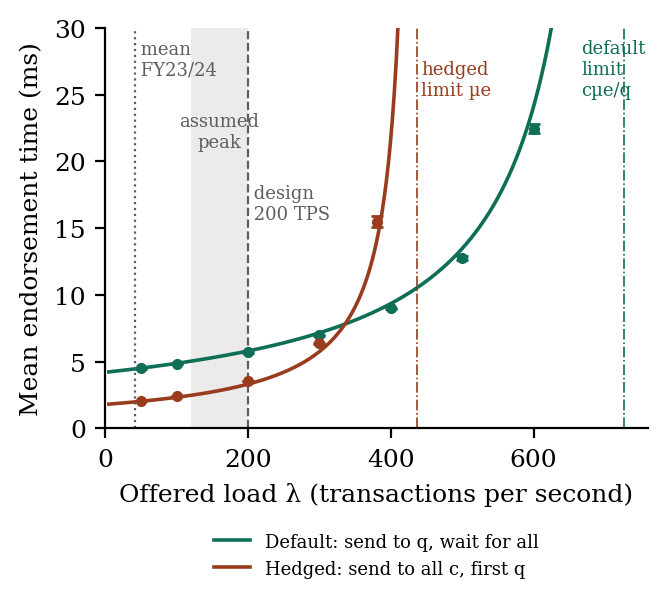

fig_validation -> regenerated


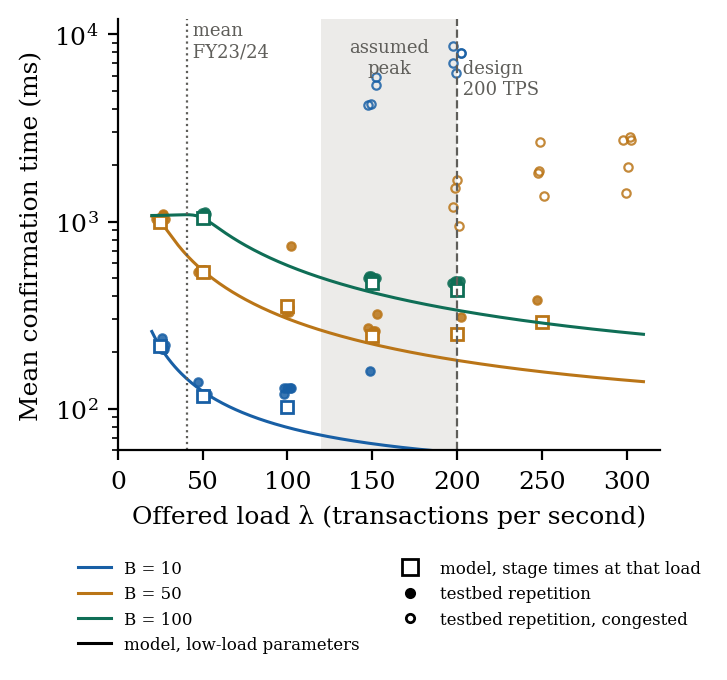

fig_block_size -> regenerated


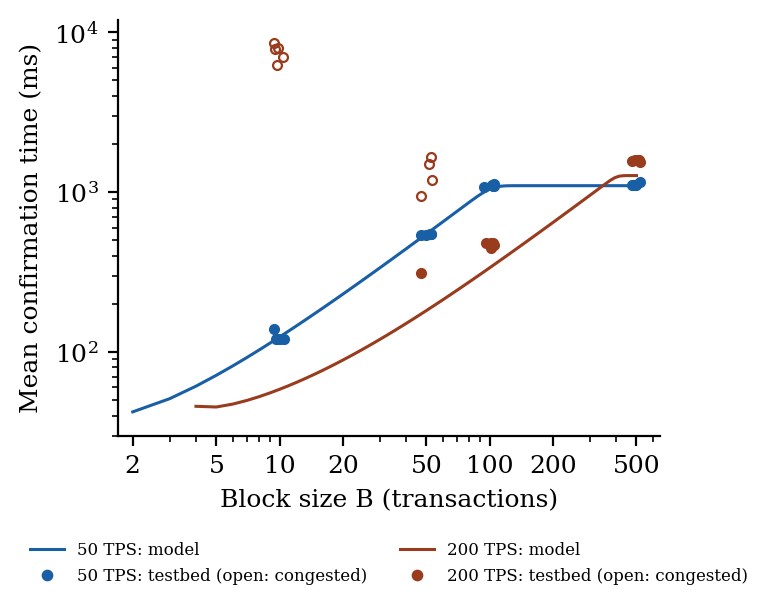

fig_institutions -> regenerated


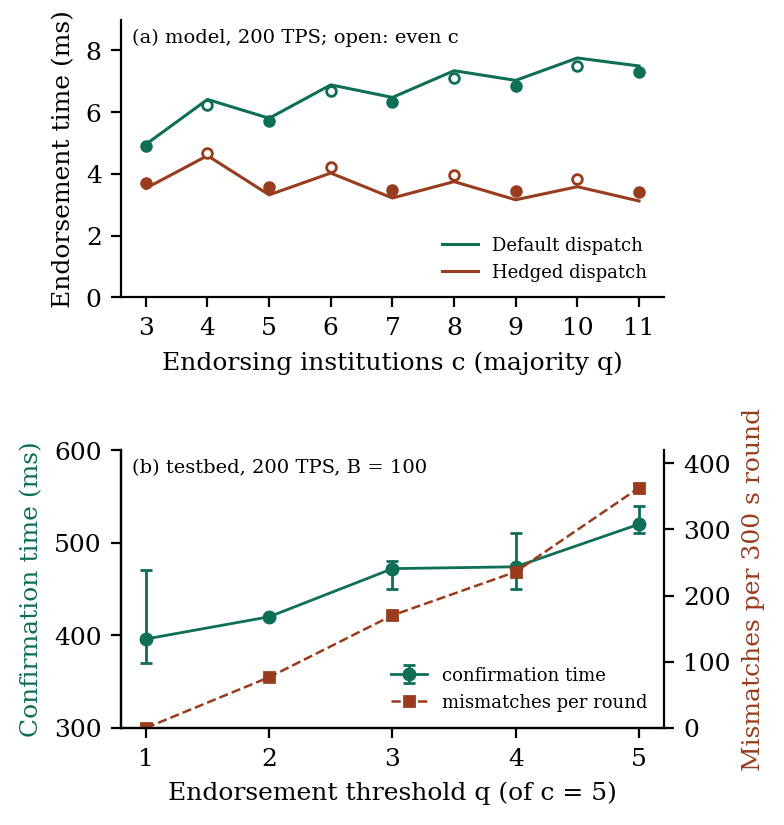

fig_surge -> saved (raw data not present)


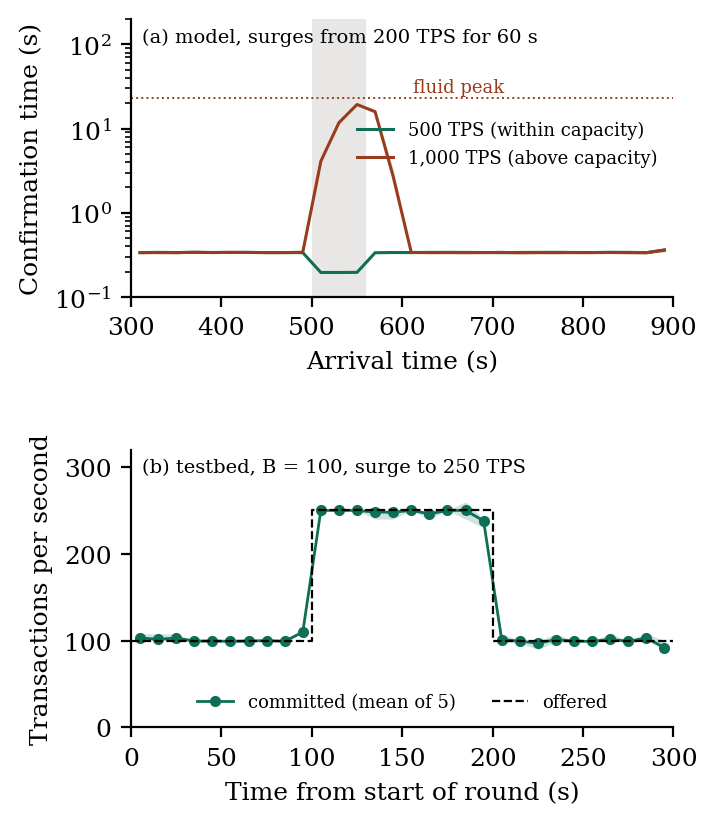

fig_loadcurve -> regenerated


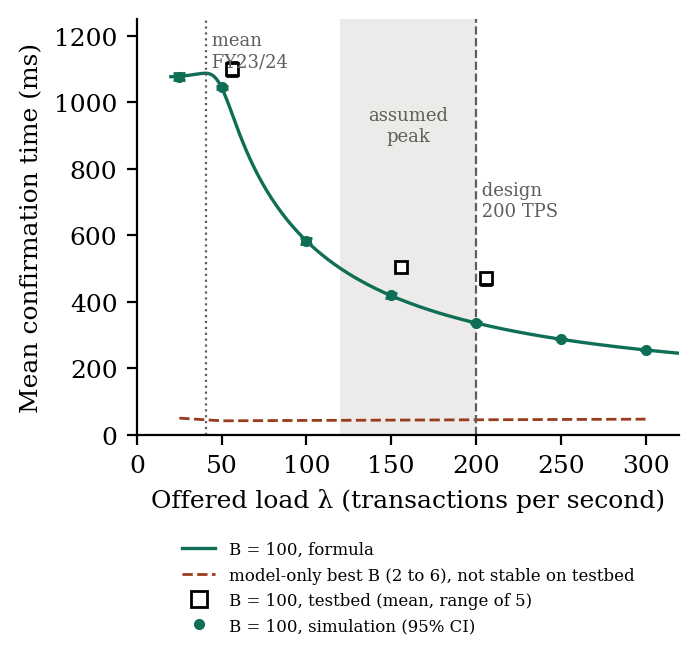

fig_contention -> regenerated


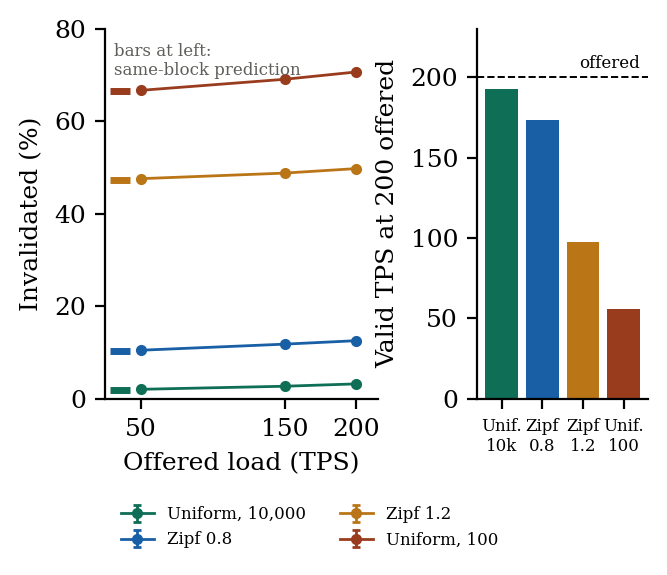

In [13]:
figs = ['fig_endorsement_dispatch', 'fig_validation', 'fig_block_size', 'fig_institutions', 'fig_surge', 'fig_loadcurve', 'fig_contention']
for f in figs:
    if f == 'fig_endorsement_dispatch':
        status = 'saved (regenerating simulates; run the script to redo)'
    else:
        r = subprocess.run([sys.executable, f + '.py'], cwd='figures/scripts', capture_output=True, text=True)
        status = 'regenerated' if r.returncode == 0 else 'saved (raw data not present)'
    print(f, '->', status); display(Image(filename=f'figures/output/{f}.png', width=420))